# Projekt 1: Analiza wielowymiarowa potencjału turystycznego regionów bałkańskich
**Autorzy:** Jan Kawalerski i Filip Kasprzycki

**Cel pracy:** 
Celem projektu jest wielowymiarowa ocena atrakcyjności turystycznej wybranych regionów na Bałkanach (poziom NUTS 2). Do analizy wykorzystano techniki porządkowania liniowego w celu stworzenia rankingu regionów oraz analizę skupień do wyodrębnienia grup o podobnej charakterystyce.


In [19]:
# Import niezbędnych bibliotek
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
import warnings

import geopandas as gpd

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")


## 1. Wczytanie danych, inżynieria cech i standaryzacja
Aby badanie miało charakter przestrzenny, skupiamy się na danych przekrojowych z najnowszego dostępnego roku (np. 2024). Na etapie inżynierii cech tworzymy **wskaźnik zagraniczności noclegów**, co pozwala usunąć wysoce współliniową kolumnę wartości bezwzględnych.

Standaryzacja danych (Z-score) sprowadza cechy o różnych rzędach wielkości do wspólnej skali, co jest krytycznym wymogiem przed analizą skupień oraz metodami porządkowania liniowego.


In [20]:
# Wczytanie danych
df_raw = pd.read_excel('baza_balkany.xlsx')
numeric_log = [
    'Noclegi_Ogolem', 
    'Liczba_Obiektow', 
    'Ruch_Lotniczy',    
]

df_raw[numeric_log] = np.log1p(df_raw[numeric_log])

df_raw['geo'] = df_raw['geo'].astype('category')



# Filtrujemy dane dla najnowszego roku
latest_year = df_raw['Year'].max()
df = df_raw[df_raw['Year'] == latest_year].copy()
df.set_index('geo', inplace=True)

# Tworzenie wskaźnika zagraniczności noclegów
df['Wskaznik_Zagranicznosci'] = df['Noclegi_Zagraniczne'] / df['Noclegi_Ogolem']

# Usunięcie surowej kolumny Noclegi_Zagraniczne w celu uniknięcia dublowania wymiarów (współliniowości)
df = df.drop(columns=['Noclegi_Zagraniczne'])

stymulanty = ['Noclegi_Ogolem', 'Liczba_Obiektow', 'Ruch_Lotniczy', 'Wody_Doskonała_Jakość_NUTS0', 'Wskaznik_Zagranicznosci']
destymulanty = ['Poziom_Cen_NUTS0', 'Robbery']
wybrane_zmienne = stymulanty + destymulanty

# Bezpieczne wyodrębnienie tylko tych zmiennych, które faktycznie istnieją w DF
dostepne_zmienne = [col for col in wybrane_zmienne if col in df.columns]
dostepne_destymulanty = [col for col in destymulanty if col in df.columns]

X = df[dostepne_zmienne].copy()

# Standaryzacja danych (Z-score)
scaler = StandardScaler()
X_std = pd.DataFrame(scaler.fit_transform(X), index=X.index, columns=X.columns)

print("Kształt danych po przygotowaniu:", X_std.shape)
display(X_std.head())


Kształt danych po przygotowaniu: (40, 7)


,Noclegi_Ogolem,Liczba_Obiektow,Ruch_Lotniczy,Wody_Doskonała_Jakość_NUTS0,Wskaznik_Zagranicznosci,Poziom_Cen_NUTS0,Robbery
geo,,,,,,,
AL01,-0.588869,-0.955138,0.902299,-0.759218,-0.402332,-0.563775,-0.519814
AL02,0.033953,-0.881888,-0.492760,-0.759218,-0.185501,-0.563775,-0.411129
AL03,-0.177227,-0.461859,-0.670036,-0.759218,-0.338121,-0.563775,-0.558257
BG31,-1.445111,-1.545430,-1.486805,-0.786854,-0.564446,-1.059220,-0.521001
BG32,-1.391953,-1.240339,-1.486805,-0.786854,-0.555532,-1.059220,-0.553037


## 2. Analiza Skupień (Grupowanie)

Etapy grupowania:
1. Obliczenie indeksu Calińskiego-Harabasza w celu numerycznego potwierdzenia optymalnej liczby klastrów.
2. **Metoda hierarchiczna (Warda)**: oparta na minimalizacji wariancji wewnątrz nowo powstających skupień (wspomagana dendrogramem).
3. **Metoda podziałowa (k-średnich)**: klasyczna metoda algorytmiczna dla zweryfikowania stabilności podziału.


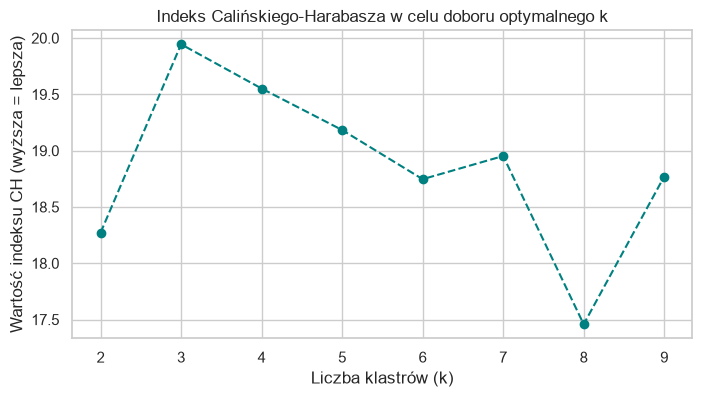

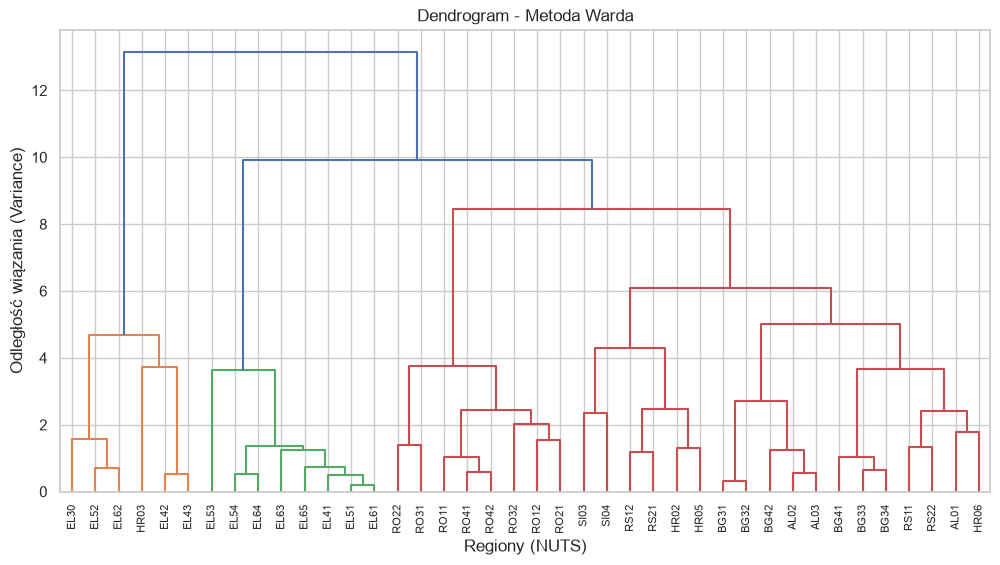


Macierz pomyłek obu metod grupowania:


K-Means,1,2,3
Ward,,,
1,0,0,6
2,0,8,0
3,21,5,0


In [21]:
# --- OCENA LICZBY KLASTRÓW (Indeks Calińskiego-Harabasza) ---
ch_scores = []
k_range = range(2, 10)

for k in k_range:
    kmeans_eval = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans_eval.fit_predict(X_std)
    ch_scores.append(calinski_harabasz_score(X_std, labels))

plt.figure(figsize=(8, 4))
plt.plot(k_range, ch_scores, marker='o', linestyle='--', color='teal')
plt.title('Indeks Calińskiego-Harabasza w celu doboru optymalnego k')
plt.xlabel('Liczba klastrów (k)')
plt.ylabel('Wartość indeksu CH (wyższa = lepsza)')
plt.show()

# Ustalamy liczbę klastrów na podstawie wykresu CH
k_clusters = 3

# --- 1. METODA WARDA I DENDROGRAM ---
Z_ward = linkage(X_std, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(Z_ward, labels=X_std.index, leaf_rotation=90)
plt.title('Dendrogram - Metoda Warda')
plt.xlabel('Regiony (NUTS)')
plt.ylabel('Odległość wiązania (Variance)')
plt.show()

# Przypisanie etykiet z metody Warda
df['Cluster_Ward'] = fcluster(Z_ward, k_clusters, criterion='maxclust')

# --- 2. METODA K-ŚREDNICH ---
kmeans = KMeans(n_clusters=k_clusters, random_state=42, n_init=10)
df['Cluster_KMeans'] = kmeans.fit_predict(X_std) + 1 

# Porównanie wyników grupowania
print("\nMacierz pomyłek obu metod grupowania:")
display(pd.crosstab(df['Cluster_Ward'], df['Cluster_KMeans'], 
                    rownames=['Ward'], colnames=['K-Means']))


## 3. Porządkowanie liniowe (Ranking)
Przeprowadzimy ocenę regionów tworząc syntetyczny miernik atrakcyjności:
1. **Metoda wzorcowa (Hellwiga)**: wykorzystuje odległość euklidesową od abstrakcyjnego punktu optymalnego ("wzorca rozwoju").
2. **Metoda bezwzorcowa**: klasyczna arytmetyczna agregacja zestawionych cech. Destymulanty zostały uprzednio przekształcone na stymulanty poprzez odwrócenie znaku.


In [22]:
# --- 1. METODA HELLWIGA (Wzorcowa) ---
# Wzorzec rozwoju: maksimum dla stymulant, minimum dla destymulant
z_ideal_hellwig = X_std.max()
z_ideal_hellwig[dostepne_destymulanty] = X_std[dostepne_destymulanty].min()

# Obliczenie odległości
d_hellwig = np.sqrt(((X_std - z_ideal_hellwig)**2).sum(axis=1))
d0 = d_hellwig.mean() + 2 * d_hellwig.std(ddof=1)
df['Hellwig_Score'] = 1 - (d_hellwig / d0)

# --- 2. METODA BEZWZORCOWA (Suma zestandaryzowana) ---
X_bez = X_std.copy()
# Destymulanty zamieniamy na stymulanty
X_bez[dostepne_destymulanty] = -X_bez[dostepne_destymulanty] 
df['Bezwzorcowa_Score'] = X_bez.sum(axis=1) / len(dostepne_zmienne)

# Tworzenie rankingów
df['Rank_Hellwig'] = df['Hellwig_Score'].rank(ascending=False).astype(int)
df['Rank_Bezwzorcowa'] = df['Bezwzorcowa_Score'].rank(ascending=False).astype(int)

# Podgląd Top 10 regionów (według metody Hellwiga)
ranking_cols = ['Hellwig_Score', 'Rank_Hellwig', 'Bezwzorcowa_Score', 'Rank_Bezwzorcowa']
print("\nTop 10 najbardziej atrakcyjnych turystycznie regionów Bałkanów:")
display(df[ranking_cols].sort_values('Rank_Hellwig').head(10))



Top 10 najbardziej atrakcyjnych turystycznie regionów Bałkanów:


,Hellwig_Score,Rank_Hellwig,Bezwzorcowa_Score,Rank_Bezwzorcowa
geo,,,,
HR03,0.744824,1,1.307420,2
EL42,0.643664,2,1.308411,1
EL43,0.613904,3,1.183914,3
EL62,0.534451,4,0.802560,4
EL52,0.483541,5,0.648257,5
EL30,0.405047,6,0.477373,6
BG34,0.378668,7,0.368441,7
SI04,0.361264,8,0.071099,13
RS11,0.344457,9,0.192575,9


## 4. Podsumowanie i interpretacja wyników
Na koniec sprawdzimy zgodność zastosowanych metod porządkowania (współczynnik Spearmana) oraz przeanalizujemy profile powstałych klastrów.


Korelacja rang Spearmana między metodą wzorcową i bezwzorcową:


,Rank_Hellwig,Rank_Bezwzorcowa
Rank_Hellwig,1.00000,0.95197
Rank_Bezwzorcowa,0.95197,1.00000



Charakterystyka klastrów (Metoda Warda) w odniesieniu do wskaźników i rankingu:


,Hellwig_Score,Bezwzorcowa_Score,Noclegi_Ogolem,Liczba_Obiektow,Wskaznik_Zagranicznosci
Cluster_Ward,,,,,
1,0.571,0.955,16.739,8.778,1074425.601
2,0.244,-0.068,14.443,6.771,82819.027
3,0.240,-0.200,14.579,7.313,90257.976


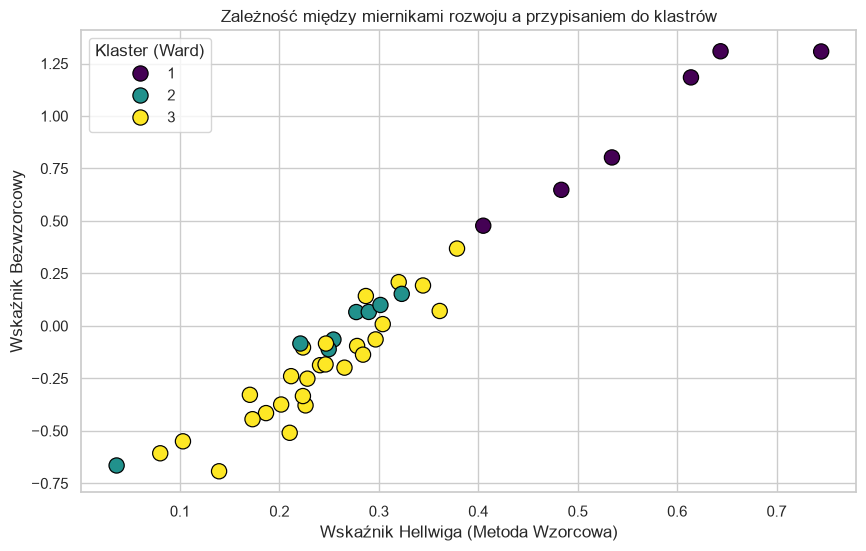

In [23]:
# Korelacja wyników z metod porządkowania
korelacja_rankingow = df[['Rank_Hellwig', 'Rank_Bezwzorcowa']].corr(method='spearman')
print("Korelacja rang Spearmana między metodą wzorcową i bezwzorcową:")
display(korelacja_rankingow)

# Profilowanie klastrów
agg_dict = {
    'Hellwig_Score': 'mean',
    'Bezwzorcowa_Score': 'mean',
    'Noclegi_Ogolem': 'mean',
    'Liczba_Obiektow': 'mean',
    'Wskaznik_Zagranicznosci': 'mean'
}

# Zabezpieczenie na wypadek brakujących kolumn
agg_dict = {k: v for k, v in agg_dict.items() if k in df.columns}

cluster_summary = df.groupby('Cluster_Ward').agg(agg_dict).round(3)

print("\nCharakterystyka klastrów (Metoda Warda) w odniesieniu do wskaźników i rankingu:")
display(cluster_summary.sort_values(by='Hellwig_Score', ascending=False))

# Wykres rozrzutu dla obu metod z kolorowaniem po klastrach
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Hellwig_Score', 
    y='Bezwzorcowa_Score', 
    hue='Cluster_Ward', 
    palette='viridis', 
    data=df, 
    s=120, 
    edgecolor='black'
)
plt.title('Zależność między miernikami rozwoju a przypisaniem do klastrów')
plt.xlabel('Wskaźnik Hellwiga (Metoda Wzorcowa)')
plt.ylabel('Wskaźnik Bezwzorcowy')
plt.legend(title='Klaster (Ward)')
plt.show()


In [24]:
# Zapis zintegrowanych wyników do pliku w celu ewentualnego raportowania w QGIS/Excelu
df.to_csv('Balkany_Wyniki_Taksonomia.csv')
print("Eksport bazy z rankingami i klastrami zakończony sukcesem (Balkany_Wyniki_Taksonomia.csv).")


Eksport bazy z rankingami i klastrami zakończony sukcesem (Balkany_Wyniki_Taksonomia.csv).


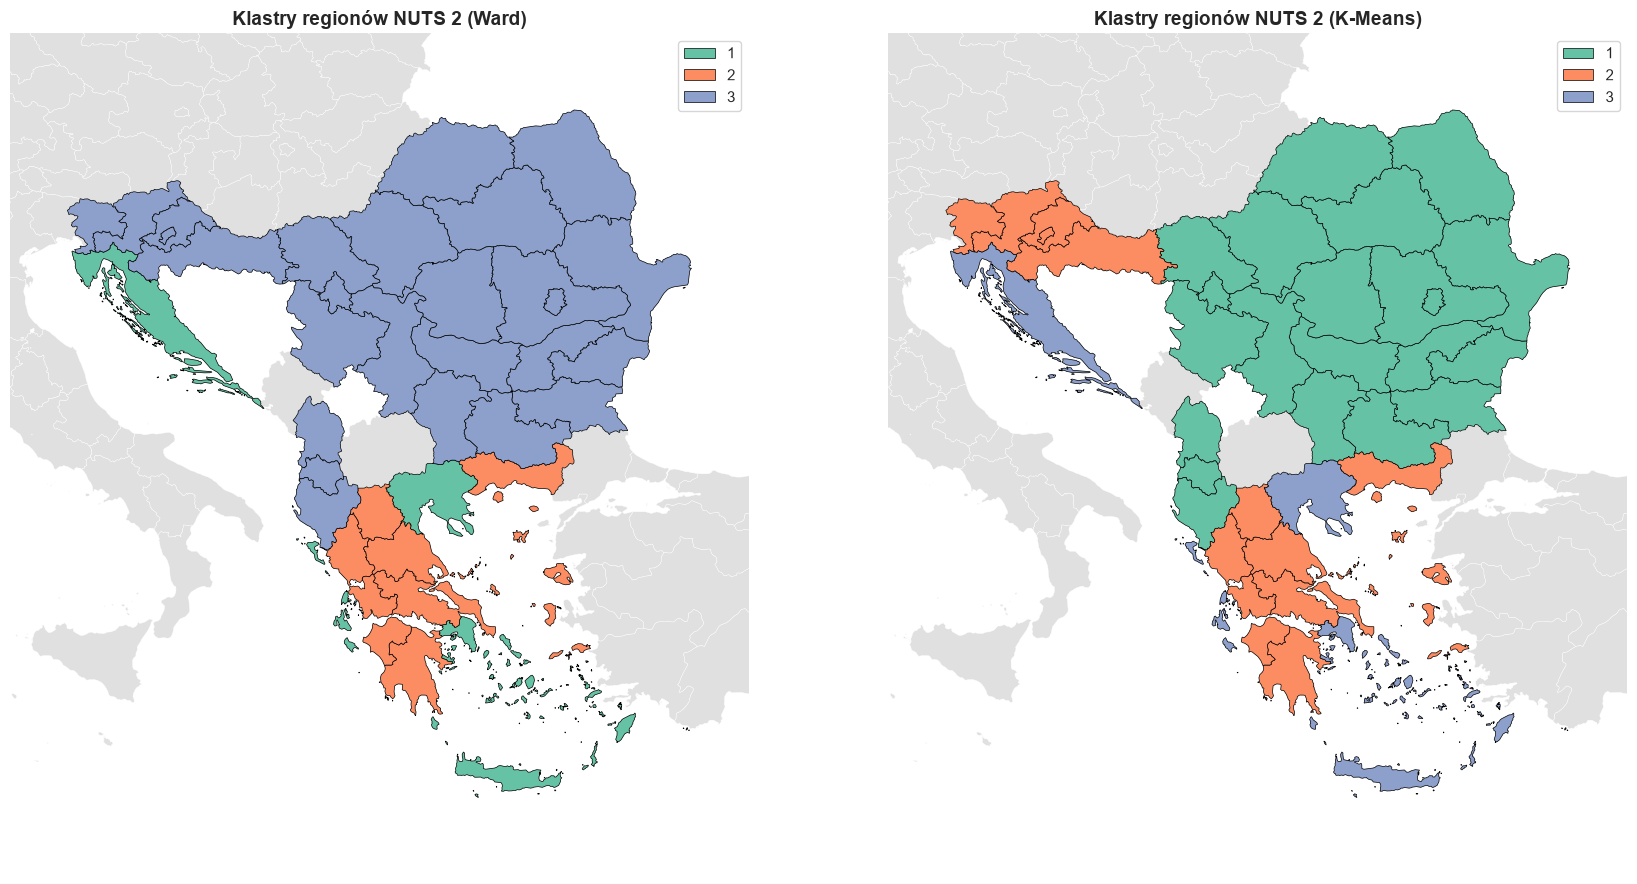

In [30]:


# 1. Pobranie granic NUTS 2 dla całej Europy

nuts2_map = gpd.read_file("https://gisco-services.ec.europa.eu/distribution/v2/nuts/geojson/NUTS_RG_03M_2021_4326_LEVL_2.geojson")

# 2. Połączenie z danymi klastrów
merged_map = nuts2_map.merge(df, left_on='NUTS_ID', right_on='geo', how='inner')

# 3. Tworzenie okna
fig, ax = plt.subplots(1, 2, figsize=(18, 9))

# Ustalenie granic kadru wokół Bałkanów (+ bufor 1.5 stopnia z każdej strony)
minx, miny, maxx, maxy = merged_map.total_bounds
margin = 1.5

# Kolory dla otoczenia
KOLOR_MORZA = "#92ccf9"      # Delikatny błękit
KOLOR_SASIADOW = '#e0e0e0'   # Jasna szarość

for a in ax:
    # Ustawienie morza jako tła wykresu
    a.set_facecolor(KOLOR_MORZA)
    
    # Warstwa 1: Wszystkie regiony Europy (tło z sąsiadami)
    nuts2_map.plot(
        ax=a, 
        color=KOLOR_SASIADOW, 
        edgecolor='white', 
        linewidth=0.3
    )

# Warstwa 2 LEWA: Klastry Ward
merged_map.plot(
    column='Cluster_Ward',
    categorical=True,
    legend=True,
    cmap='Set2',
    edgecolor='black',
    linewidth=0.5,
    ax=ax[0]
)
ax[0].set_title('Klastry regionów NUTS 2 (Ward)', fontsize=14, fontweight='bold')

# Warstwa 2 PRAWA: Klastry K-Means
merged_map.plot(
    column='Cluster_KMeans',
    categorical=True,
    legend=True,
    cmap='Set2',
    edgecolor='black',
    linewidth=0.5,
    ax=ax[1]
)
ax[1].set_title('Klastry regionów NUTS 2 (K-Means)', fontsize=14, fontweight='bold')

# Kadrowanie widoku do obszaru Bałkanów
for a in ax:
    a.set_xlim(minx - margin, maxx + margin)
    a.set_ylim(miny - margin, maxy + margin)
    a.axis('off')  # Ukrycie ramki i osi ze współrzędnymi
    

plt.tight_layout()
plt.show()

Porównajmy teraz ze soba powstałe klastry 

In [53]:
dane_klaster_srednie = df.groupby('Cluster_KMeans').mean(numeric_only=True)





In [54]:
print(dane_klaster_srednie.columns)
print(dane_klaster_srednie.head())

Index(['Year', 'Noclegi_Ogolem', 'Liczba_Obiektow', 'Ruch_Lotniczy',
       'Poziom_Cen_NUTS0', 'Wody_Doskonała_Jakość_NUTS0', 'Robbery',
       'Wskaznik_Zagranicznosci', 'Cluster_Ward', 'Hellwig_Score',
       'Bezwzorcowa_Score', 'Rank_Hellwig', 'Rank_Bezwzorcowa'],
      dtype='str')
                  Year  Noclegi_Ogolem  Liczba_Obiektow  Ruch_Lotniczy  \
Cluster_KMeans                                                           
1               2024.0       14.665681         7.136734       4.749241   
2               2024.0       14.355737         7.263268       4.481484   
3               2024.0       16.738943         8.777566       9.400506   

                Poziom_Cen_NUTS0  Wody_Doskonała_Jakość_NUTS0      Robbery  \
Cluster_KMeans                                                               
1                      58.804762                    72.142857  4741.714286   
2                      81.992308                  1272.923077   432.692308   
3                      81.38

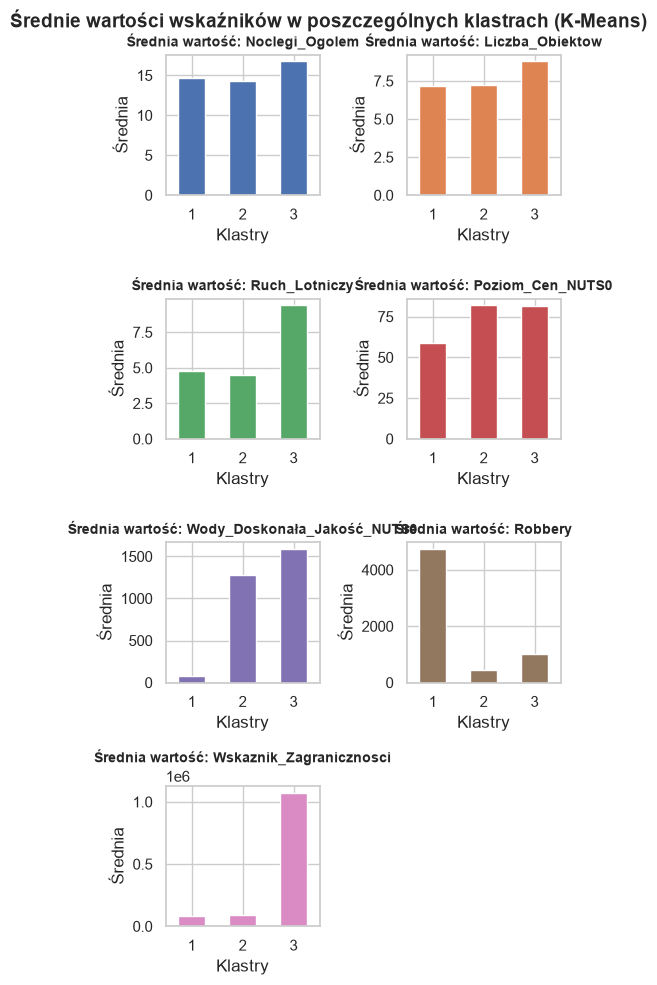

In [66]:
numeric_log = ['Noclegi_Ogolem','Liczba_Obiektow','Ruch_Lotniczy','Poziom_Cen_NUTS0','Wody_Doskonała_Jakość_NUTS0', 'Robbery','Wskaznik_Zagranicznosci' ]

# Zwiększamy wysokość (np. 12 lub 15), aby 5 wykresów było czytelnych
plt.figure(figsize=(5, 17))

for i, col in enumerate(numeric_log):
    # Tworzymy kolejny podwykres w pętli (5 wierszy, 1 kolumna, numeracja od 1)
    plt.subplot(len(numeric_log), 2, i + 1)
    
    dane_klaster_srednie[col].plot(kind='bar', ax=plt.gca(), color=f'C{i}', width=0.52)
    
    plt.title(f'Średnia wartość: {col}', fontsize=10, fontweight='bold')
    plt.xlabel('Klastry')
    plt.ylabel('Średnia')
    plt.xticks(rotation=0)

plt.suptitle('Średnie wartości wskaźników w poszczególnych klastrach (K-Means)', fontsize=14, fontweight='bold')
plt.tight_layout()  # Zapobiega nachodzeniu na siebie podpisów
plt.show()
